# Qualitative Diagnostic Analysis: Identity Performance, Inter-Identity Confusion, & Gallery Sensitivity

This notebook investigates the intrinsic visual factors, recording conditions, and retrieval error patterns that govern dog re-identification in **DogReID-1553**.

### Core Experiments:
1. **Best- vs. Worst-Performing Identity Analysis**:
   - Compute per-identity mAP across all 680 closed-world test identities.
   - Select the 10 best-performing and 10 worst-performing identities.
   - Extract representative query and gallery video crops for each selected identity.
   - Characterize each identity across **Dataset representation** (query/gallery support), **Visual Appearance** (coat pattern, colour, breed/type, body size, distinctive marks), and **Recording conditions** (video quality, viewpoint variation, visibility, occlusion).
   - Determine whether failure modes are primarily associated with visually ambiguous dogs or challenging recording conditions.

2. **Inter-Identity Similarity and Confusion Analysis**:
   - Analyze incorrect top-ranked predictions across all query tracklets.
   - Distinguish between **Unidirectional Confusion** ($A \to B$) and **Mutual Confusion** ($A \leftrightarrow B$, where Dog $A$ retrieves Dog $B$ AND Dog $B$ retrieves Dog $A$).
   - Identify the 10–20 most frequently confused identity pairs and compare their visual characteristics.
   - Present representative retrieval triplets: *(Query Dog A, False Top-1 Match Dog B, True Gallery Match Dog A)*.

3. **Gallery Size Sensitivity Analysis (Transferred & Enhanced)**:
   - **Volume Scaling**: Retrieval degradation across total gallery video counts (38.9% / 777 videos up to 100% / 1,998 videos) with 100-iteration bootstrap confidence intervals.
   - **Identity Scaling**: Retrieval degradation as the number of competing distractor identities in the gallery increases from 100 to 777 unique dogs.

In [40]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import pickle
from collections import defaultdict, Counter
from IPython.display import display

# Add root directory to sys.path
CURRENT_DIR = Path.cwd()
ROOT_DIR = CURRENT_DIR
for p in [CURRENT_DIR, CURRENT_DIR.parent, CURRENT_DIR.parent.parent]:
    if (p / "splits.csv").exists() and (p / "evaluation").exists():
        ROOT_DIR = p
        break
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
if str(ROOT_DIR / "evaluation") not in sys.path:
    sys.path.append(str(ROOT_DIR / "evaluation"))

FIG_DIR = ROOT_DIR / "evaluation" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {ROOT_DIR}")
print(f"Figure output directory: {FIG_DIR}")

# Set consistent matplotlib publication style
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 16,
    'font.family': 'sans-serif',
})


Project root: c:\Users\marko\Desktop\DogReID-1553
Figure output directory: c:\Users\marko\Desktop\DogReID-1553\evaluation\figures


In [41]:
# =====================================================================
# Bounding Box Index & High-Precision Image Cropping Helper
# =====================================================================
BBOX_CSV = ROOT_DIR / "bounding_boxes.csv"
bbox_df = pd.read_csv(BBOX_CSV)
bbox_map = {
    (str(r["DOG_ID"]), str(r["VIDEO_ID"])): (
        int(r["x_top_left"]), int(r["y_top_left"]), int(r["width"]), int(r["height"])
    )
    for _, r in bbox_df.iterrows()
}
print(f"Loaded {len(bbox_map)} ground truth bounding boxes from {BBOX_CSV.name}.")

def load_dog_crop(dog_id, video_id=None, pad=0.08):
    """Load and crop dog frame using ground-truth bounding box with padding."""
    dog_dir = ROOT_DIR / "Images" / str(dog_id)
    if not dog_dir.exists():
        return None
    if video_id is None:
        files = sorted(list(dog_dir.glob("*.jpg")))
        if not files: return None
        img_path = files[0]
        v_id = img_path.stem[37:]  # UUID is 36 chars + 1 hyphen
    else:
        img_path = dog_dir / f"{dog_id}-{video_id}.jpg"
        v_id = str(video_id)
        if not img_path.exists():
            files = sorted(list(dog_dir.glob("*.jpg")))
            if not files: return None
            img_path = files[0]
            v_id = img_path.stem[37:]
    try:
        im = Image.open(img_path).convert("RGB")
        box = bbox_map.get((str(dog_id), str(v_id)))
        if box:
            x, y, w, h = box
            x1 = max(0, int(x - w * pad))
            y1 = max(0, int(y - h * pad))
            x2 = min(im.width, int(x + w * (1.0 + pad)))
            y2 = min(im.height, int(y + h * (1.0 + pad)))
            if x2 > x1 and y2 > y1:
                im = im.crop((x1, y1, x2, y2))
        return im
    except Exception as e:
        return None

Loaded 7463 ground truth bounding boxes from bounding_boxes.csv.


## 1. Best- vs. Worst-Performing Identity Analysis

**Objective**: Investigate which intrinsic visual characteristics (coat patterns, breed, morphology) and recording conditions (viewpoint, distance, illumination, occlusions) are associated with easier vs. more difficult dog re-identification.

### Procedure:
1. Calculate per-identity mAP for all test identities from the closed-world baseline distance matrix.
2. Select the **10 best-performing** and **10 worst-performing** identities (filtering for identities with multiple queries for robust ranking).
3. Collect and visualize representative query and gallery crops for each identity.
4. Provide structured attribute annotations across **Dataset representation**, **Appearance**, and **Recording conditions**.

In [42]:
# =====================================================================
# Compute Per-Identity mAP & Rank-1 Accuracy
# =====================================================================
baseline_csv = ROOT_DIR / "evaluation" / "csvs_closed_results" / "baseline_vid2vid" / "closed_dist_matrix.csv"
assert baseline_csv.exists(), f"Baseline CSV missing at {baseline_csv}"

df_full = pd.read_csv(baseline_csv)
get_id = lambda x: str(x).rsplit('_', 1)[0]
get_vid = lambda x: str(x).rsplit('_', 1)[1] if '_' in str(x) else str(x)

query_ids = np.array(df_full['queryId'].values)
gallery_ids = np.array(df_full.columns[1:].values)

query_labels = np.array([get_id(i) for i in query_ids])
gallery_labels = np.array([get_id(i) for i in gallery_ids])
dist_mat = df_full.iloc[:, 1:].values.astype(np.float32)

print(f"Loaded closed-world distance matrix: {len(query_labels)} queries x {len(gallery_labels)} gallery tracks.")
print(f"Unique query identities: {len(np.unique(query_labels))} | Unique gallery identities: {len(np.unique(gallery_labels))}")

# Pairwise match matrix & sorted indices
match_matrix = query_labels[:, None] == gallery_labels[None, :]
sort_idx = np.argsort(dist_mat, axis=1)
sorted_matches = np.take_along_axis(match_matrix, sort_idx, axis=1)

# Calculate per-query Average Precision (AP) and Rank-1 hit
ap_list = []
for i in range(len(query_labels)):
    row_m = sorted_matches[i]
    if not np.any(row_m):
        ap_list.append(0.0)
        continue
    cum_m = np.cumsum(row_m)
    rank_pos = np.where(row_m)[0] + 1.0
    precision = cum_m[row_m] / rank_pos
    ap_list.append(float(np.mean(precision)))

df_query_stats = pd.DataFrame({
    'query_id': query_ids,
    'dog_id': query_labels,
    'video_id': [get_vid(i) for i in query_ids],
    'AP': ap_list,
    'rank1': sorted_matches[:, 0].astype(int)
})

# Aggregate per-identity statistics
id_stats = df_query_stats.groupby('dog_id').agg(
    n_queries=('AP', 'count'),
    mAP=('AP', 'mean'),
    rank1_acc=('rank1', 'mean')
).reset_index()

gallery_counts = pd.Series(gallery_labels).value_counts()
id_stats['n_gallery'] = id_stats['dog_id'].map(gallery_counts).fillna(0).astype(int)
id_stats['mAP_pct'] = id_stats['mAP'] * 100.0
id_stats['rank1_pct'] = id_stats['rank1_acc'] * 100.0

print(f"\nSummary across all {len(id_stats)} identities:")
print(f"  Mean mAP          : {id_stats['mAP_pct'].mean():.2f}%")
print(f"  Median mAP        : {id_stats['mAP_pct'].median():.2f}%")
print(f"  Identities @ 100% : {sum(id_stats['mAP'] == 1.0)} ({sum(id_stats['mAP'] == 1.0)/len(id_stats)*100:.1f}%)")
print(f"  Identities @ 0%   : {sum(id_stats['rank1_acc'] == 0.0)} ({sum(id_stats['rank1_acc'] == 0.0)/len(id_stats)*100:.1f}%)")

Loaded closed-world distance matrix: 1677 queries x 1998 gallery tracks.
Unique query identities: 680 | Unique gallery identities: 777

Summary across all 680 identities:
  Mean mAP          : 58.05%
  Median mAP        : 59.06%
  Identities @ 100% : 109 (16.0%)
  Identities @ 0%   : 147 (21.6%)



Video Count Summary:
   Group Mean Query Videos Mean Gallery Videos  Total Query Videos  Total Gallery Videos
 Best 10               2.3                 1.9                  23                    19
Worst 10               3.0                 1.2                  30                    12

Analysis completed.
Generated figures:
C:\Users\marko\Desktop\DogReID-1553\evaluation\figures\best_vs_worst_query_gallery_grouped_bars.png
C:\Users\marko\Desktop\DogReID-1553\evaluation\figures\best_vs_worst_query_gallery_grouped_bars.pdf


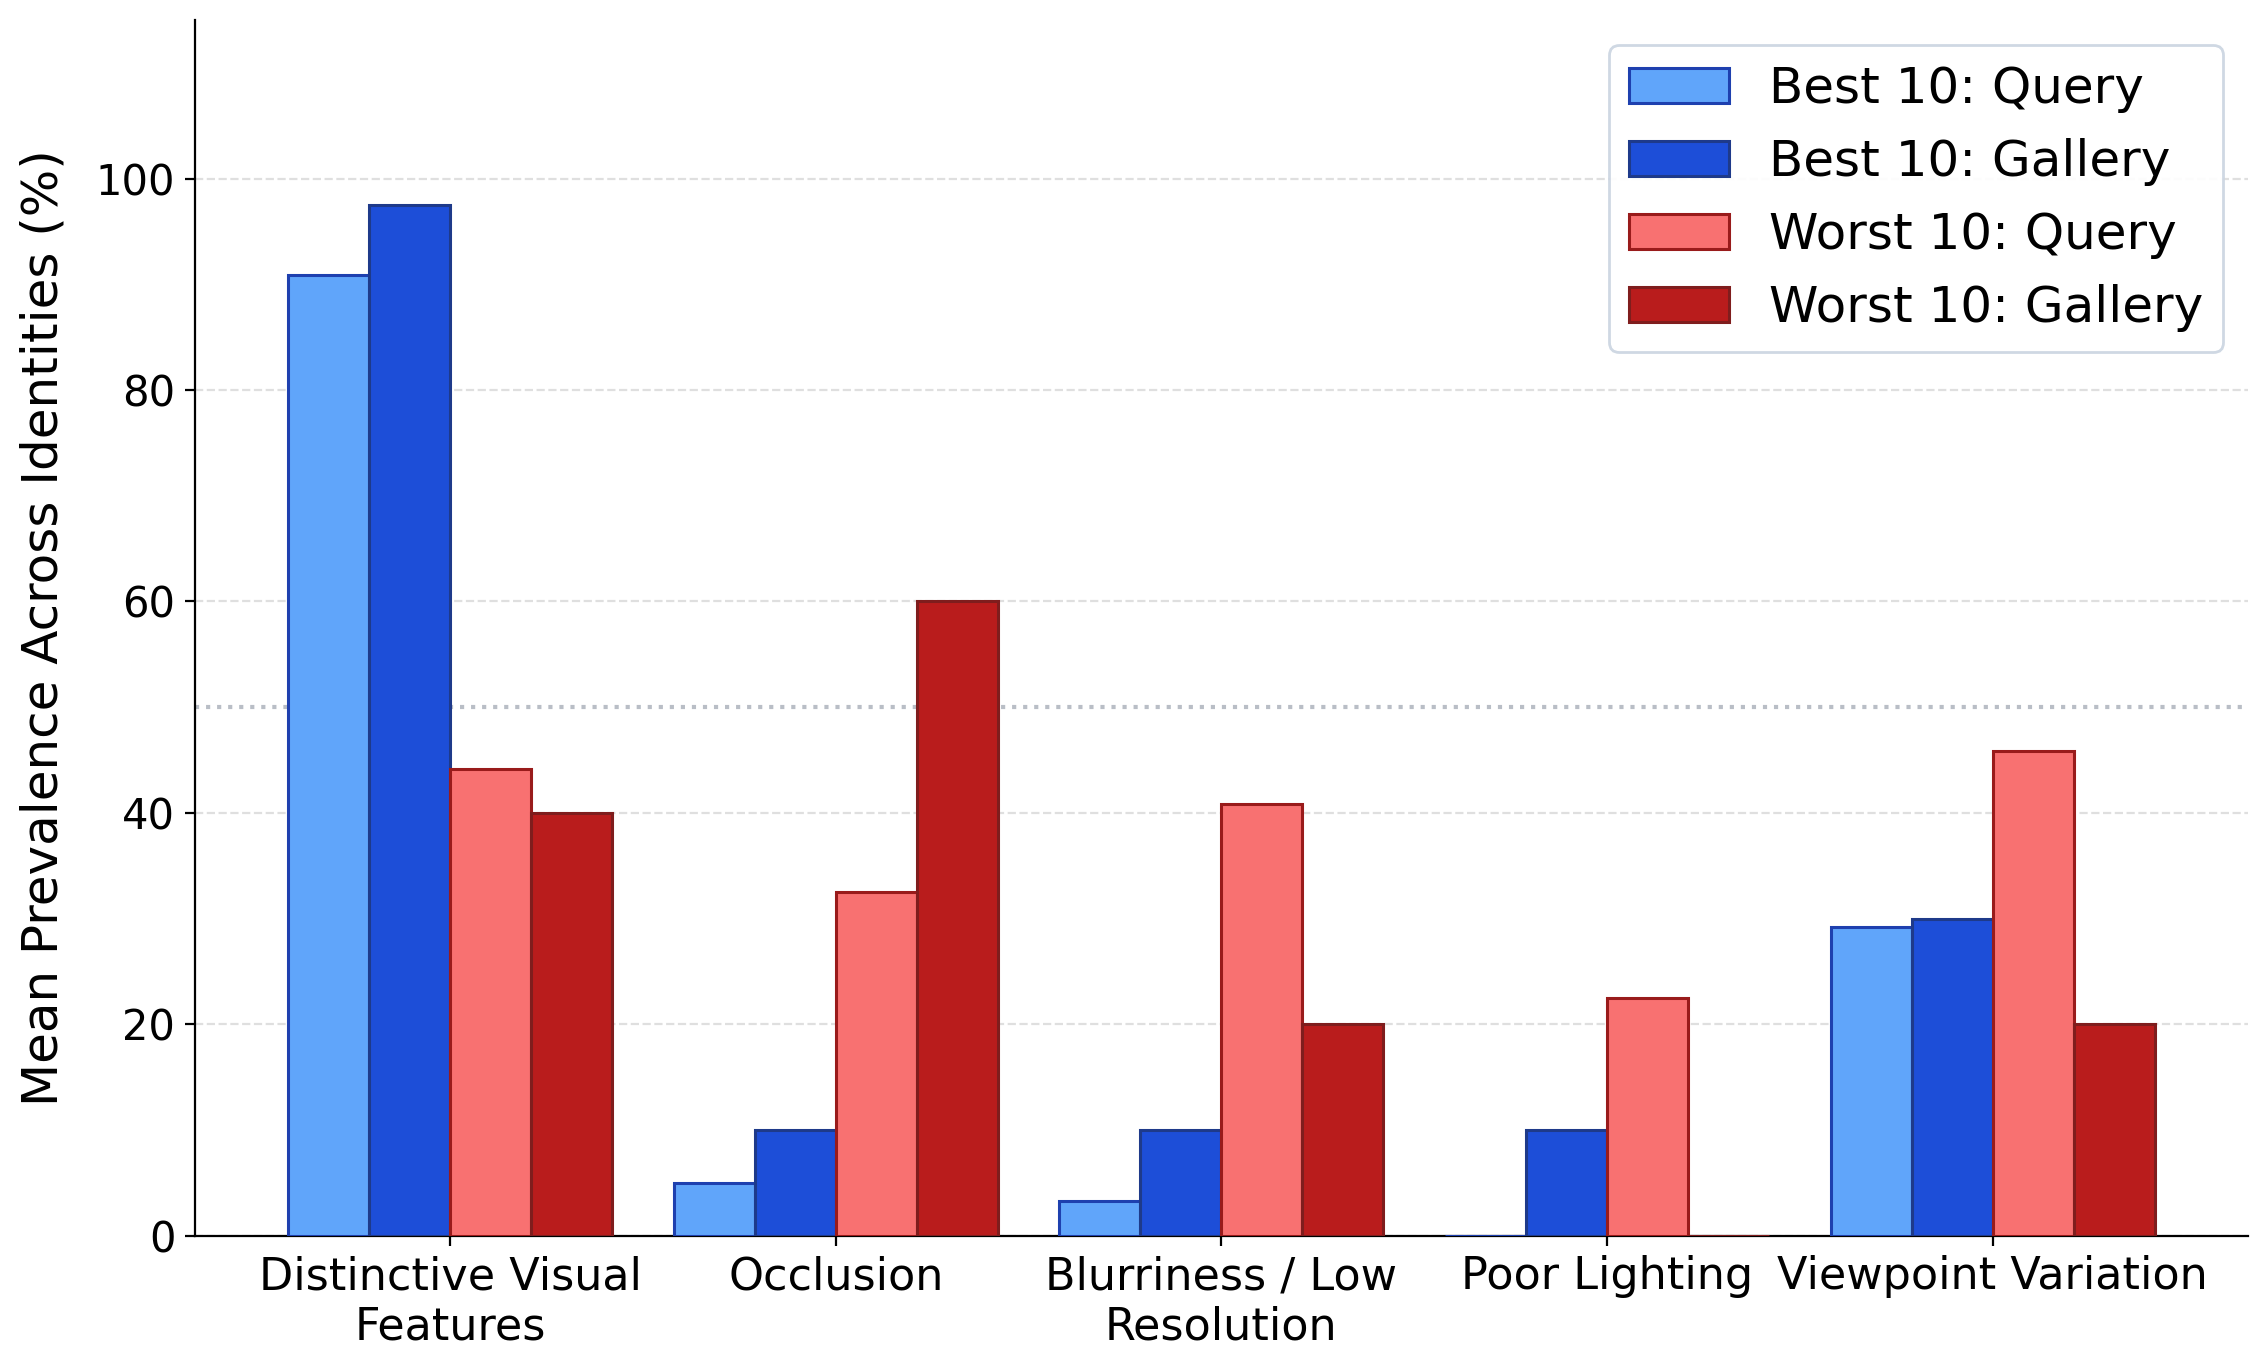

In [65]:
# =====================================================================
# 9. Main Figure: Grouped Bar Chart
# =====================================================================

fig, ax = plt.subplots(
    figsize=(11.5, 7.0),
    dpi=200
)

x = np.arange(len(prop_names))
w = 0.21

# Full, consistently capitalized property names
display_prop_names = [
    "Distinctive Visual\nFeatures",
    "Occlusion",
    "Blurriness / Low\nResolution",
    "Poor Lighting",
    "Viewpoint Variation"
]

# Convert prevalence values from [0, 1] to percentages
best_q_pct = np.array(best_q_means) * 100
best_g_pct = np.array(best_g_means) * 100
worst_q_pct = np.array(worst_q_means) * 100
worst_g_pct = np.array(worst_g_means) * 100

# Best 10: Query
b1 = ax.bar(
    x - 1.5 * w,
    best_q_pct,
    w,
    label="Best 10: Query",
    color="#60a5fa",
    edgecolor="#1e40af",
    linewidth=1.1,
    zorder=3
)

# Best 10: Gallery
b2 = ax.bar(
    x - 0.5 * w,
    best_g_pct,
    w,
    label="Best 10: Gallery",
    color="#1d4ed8",
    edgecolor="#1e3a8a",
    linewidth=1.1,
    zorder=3
)

# Worst 10: Query
b3 = ax.bar(
    x + 0.5 * w,
    worst_q_pct,
    w,
    label="Worst 10: Query",
    color="#f87171",
    edgecolor="#991b1b",
    linewidth=1.1,
    zorder=3
)

# Worst 10: Gallery
b4 = ax.bar(
    x + 1.5 * w,
    worst_g_pct,
    w,
    label="Worst 10: Gallery",
    color="#b91c1c",
    edgecolor="#7f1d1d",
    linewidth=1.1,
    zorder=3
)


# =====================================================================
# 10. Figure Formatting
# =====================================================================

ax.set_xticks(x)

ax.set_xticklabels(
    display_prop_names,
    fontsize=16
)

ax.tick_params(
    axis="x",
    labelsize=16
)

ax.tick_params(
    axis="y",
    labelsize=15
)

ax.set_ylabel(
    "Mean Prevalence Across Identities (%)",
    fontsize=18,
    labelpad=10
)

ax.set_ylim(0, 115)

ax.axhline(
    50,
    color="#9ca3af",
    linestyle=":",
    alpha=0.7,
    zorder=2
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.legend(
    loc="upper right",
    frameon=True,
    facecolor="white",
    framealpha=0.92,
    edgecolor="#cbd5e1",
    fontsize=18
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# =====================================================================
# 11. Print Video Count Summary Table
# =====================================================================

best_counts = count_stats["Best 10"]
worst_counts = count_stats["Worst 10"]

video_count_table = pd.DataFrame(
    [
        {
            "Group": "Best 10",
            "Mean Query Videos": best_counts["query_mean"],
            "Mean Gallery Videos": best_counts["gallery_mean"],
            "Total Query Videos": best_counts["query_total"],
            "Total Gallery Videos": best_counts["gallery_total"],
        },
        {
            "Group": "Worst 10",
            "Mean Query Videos": worst_counts["query_mean"],
            "Mean Gallery Videos": worst_counts["gallery_mean"],
            "Total Query Videos": worst_counts["query_total"],
            "Total Gallery Videos": worst_counts["gallery_total"],
        }
    ]
)

print("\nVideo Count Summary:")

print(
    video_count_table.to_string(
        index=False,
        formatters={
            "Mean Query Videos": "{:.1f}".format,
            "Mean Gallery Videos": "{:.1f}".format,
        }
    )
)


# =====================================================================
# 12. Save and Display Figure
# =====================================================================

FIG_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_PNG = FIG_DIR / "best_vs_worst_query_gallery_grouped_bars.png"
FIGURE_PDF = FIG_DIR / "best_vs_worst_query_gallery_grouped_bars.pdf"

fig.savefig(
    FIGURE_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURE_PDF,
    format="pdf",
    bbox_inches="tight"
)

print("\nAnalysis completed.")
print("Generated figures:")
print(FIGURE_PNG.resolve())
print(FIGURE_PDF.resolve())

plt.show()

## 2. Inter-Identity Similarity and Confusion Analysis

**Objective**: Identify dogs that the model frequently confuses with one another and investigate the reasons behind these misidentifications.

### Confusion Types:
1. **Unidirectional Confusion** ($A \to B$): Query videos of Dog $A$ frequently match with gallery videos of Dog $B$ at Rank-1, but queries of Dog $B$ do not retrieve Dog $A$.
2. **Mutual Confusion** ($A \leftrightarrow B$): Queries of Dog $A$ retrieve Dog $B$ at Rank-1, **AND** queries of Dog $B$ retrieve Dog $A$ at Rank-1. Mutual confusion is the strongest indicator that two identities are visually ambiguous or nearly indistinguishable for the visual encoder.

In [44]:
# =====================================================================
# Compute Unidirectional and Mutual Confusion Pairs
# =====================================================================
unidirectional_counts = Counter()
pair_confusion_stats = defaultdict(lambda: {
    'A_to_B_top1': 0, 'B_to_A_top1': 0,
    'A_to_B_top5': 0, 'B_to_A_top5': 0,
    'examples_A': [], 'examples_B': []
})

for i, q_label in enumerate(query_labels):
    q_item = query_ids[i]
    q_vid = get_vid(q_item)
    ranked_g_labels = gallery_labels[sort_idx[i]]
    ranked_g_items = gallery_ids[sort_idx[i]]
    
    top1_g_label = ranked_g_labels[0]
    top1_g_item = ranked_g_items[0]
    
    # Record Top-1 error
    if top1_g_label != q_label:
        unidirectional_counts[(q_label, top1_g_label)] += 1
        pair = tuple(sorted([q_label, top1_g_label]))
        if q_label == pair[0]:
            pair_confusion_stats[pair]['A_to_B_top1'] += 1
            pair_confusion_stats[pair]['examples_A'].append((q_vid, get_vid(top1_g_item)))
        else:
            pair_confusion_stats[pair]['B_to_A_top1'] += 1
            pair_confusion_stats[pair]['examples_B'].append((q_vid, get_vid(top1_g_item)))
            
    # Record Top-5 errors
    for r in range(5):
        g_lab = ranked_g_labels[r]
        if g_lab != q_label:
            pair = tuple(sorted([q_label, g_lab]))
            if q_label == pair[0]:
                pair_confusion_stats[pair]['A_to_B_top5'] += 1
            else:
                pair_confusion_stats[pair]['B_to_A_top5'] += 1

# 1. Mutual Confusions (Both A->B > 0 and B->A > 0)
mutual_list = []
for pair, data in pair_confusion_stats.items():
    if data['A_to_B_top1'] > 0 and data['B_to_A_top1'] > 0:
        tot_top1 = data['A_to_B_top1'] + data['B_to_A_top1']
        tot_top5 = data['A_to_B_top5'] + data['B_to_A_top5']
        mutual_list.append({
            'Dog A': pair[0],
            'Dog B': pair[1],
            'Short A': pair[0][:8] + '...',
            'Short B': pair[1][:8] + '...',
            'A_to_B (Top-1)': data['A_to_B_top1'],
            'B_to_A (Top-1)': data['B_to_A_top1'],
            'Total Top-1 Mutual': tot_top1,
            'Total Top-5 Mutual': tot_top5,
            'data': data
        })

df_mutual = pd.DataFrame(mutual_list).sort_values(
    by=['Total Top-1 Mutual', 'Total Top-5 Mutual'], ascending=[False, False]
).reset_index(drop=True)

# 2. Top Unidirectional Confusions
unidir_list = []
for (q_id, g_id), cnt in unidirectional_counts.most_common(15):
    unidir_list.append({
        'Query Dog (A)': q_id,
        'False Gallery Match (B)': g_id,
        'Short Query': q_id[:8] + '...',
        'Short False Match': g_id[:8] + '...',
        'Error Count (Top-1)': cnt
    })
df_unidir = pd.DataFrame(unidir_list)

print(f"Found {len(df_mutual)} mutual confusion pairs in the closed-world test set.")
print("\n=== Top Mutual Confusion Pairs (Bidirectional Retrieval Failures) ===")
display(df_mutual[['Short A', 'Short B', 'A_to_B (Top-1)', 'B_to_A (Top-1)', 'Total Top-1 Mutual', 'Total Top-5 Mutual']])

print("\n=== Top Unidirectional Confusions (Query Dog A -> Retrieved Dog B) ===")
display(df_unidir[['Short Query', 'Short False Match', 'Error Count (Top-1)']])

Found 16 mutual confusion pairs in the closed-world test set.

=== Top Mutual Confusion Pairs (Bidirectional Retrieval Failures) ===


,Short A,Short B,A_to_B (Top-1),B_to_A (Top-1),Total Top-1 Mutual,Total Top-5 Mutual
0,55f461ae...,e57001df...,3,1,4,8
1,1aadfd14...,22a635ce...,1,2,3,5
2,3b1e4347...,92673b1a...,1,2,3,5
3,77eb8911...,fe7822e8...,1,2,3,5
4,40989388...,509a29ff...,1,1,2,8
5,96242e26...,a61b868a...,1,1,2,8
6,1106673b...,3e600a3f...,1,1,2,7
7,33c234be...,46cbca2f...,1,1,2,7
8,89b8b288...,c9dc8631...,1,1,2,7
9,53303749...,edd2da4e...,1,1,2,6



=== Top Unidirectional Confusions (Query Dog A -> Retrieved Dog B) ===


,Short Query,Short False Match,Error Count (Top-1)
0,48f4d193...,7faa5277...,4
1,a7a63eb7...,219ab714...,4
2,c28d6906...,5e56ead4...,4
3,0328c4c1...,4465c22c...,3
4,1c860ce3...,9a2e512f...,3
5,38c2af2b...,bab3d69f...,3
6,51a8d009...,2a96b205...,3
7,552e12e0...,839f135a...,3
8,55f461ae...,e57001df...,3
9,5780cf06...,23c3dfb1...,3


In [45]:
# =====================================================================
# Structured Confusion Pairs Comparison Table for User Annotation
# =====================================================================
conf_table_rows = []
for idx, row in df_mutual.head(10).iterrows():
    conf_table_rows.append({
        'Confusion Type': 'Mutual',
        'Dog A (ID)': row['Dog A'],
        'Dog B (ID)': row['Dog B'],
        'Top-1 Count': row['Total Top-1 Mutual'],
        'Top-5 Count': row['Total Top-5 Mutual'],
        'Dog A Breed / Type': '',
        'Dog B Breed / Type': '',
        'Shared Coat Colour': '',
        'Shared Pattern / Markings': '',
        'Shared Silhouette / Ear Shape': '',
        'Key Discriminating Feature Missed': ''
    })

for idx, row in df_unidir.head(10).iterrows():
    conf_table_rows.append({
        'Confusion Type': 'Unidirectional',
        'Dog A (ID)': row['Query Dog (A)'],
        'Dog B (ID)': row['False Gallery Match (B)'],
        'Top-1 Count': row['Error Count (Top-1)'],
        'Top-5 Count': '-',
        'Dog A Breed / Type': '',
        'Dog B Breed / Type': '',
        'Shared Coat Colour': '',
        'Shared Pattern / Markings': '',
        'Shared Silhouette / Ear Shape': '',
        'Key Discriminating Feature Missed': ''
    })

df_conf_annotation = pd.DataFrame(conf_table_rows)
# display(df_conf_annotation)

# Save template to CSV
df_conf_annotation.to_csv(ROOT_DIR / "evaluation" / "failure_case" / "confusion_pairs_annotation_template.csv", index=False)
print("-> Saved confusion annotation template to evaluation/failure_case/confusion_pairs_annotation_template.csv")


-> Saved confusion annotation template to evaluation/failure_case/confusion_pairs_annotation_template.csv


### Visual Confounding Factors Breakdown (Top 20 Confused Pairs)

Quantifies the prevalence of each of the 5 visual morphological properties contributing to identity confusion across the 20 most frequently confused identity pairs.


,Visual Property,Similarity Count,Total Evaluated,Similarity (%),Non-Similarity Count,Non-Similarity (%)
0,Body Shape,20,20,100.0,0,0.0
1,Breed,18,20,90.0,2,10.0
2,Coat Colour,18,20,90.0,2,10.0
3,Coat Pattern,14,20,70.0,6,30.0
4,Facial Appearance,9,20,45.0,11,55.0


-> PDF saved to: C:\Users\marko\Desktop\DogReID-1553\evaluation\figures\confusion_properties_percentage.pdf
-> PNG saved to: C:\Users\marko\Desktop\DogReID-1553\evaluation\figures\confusion_properties_percentage.png


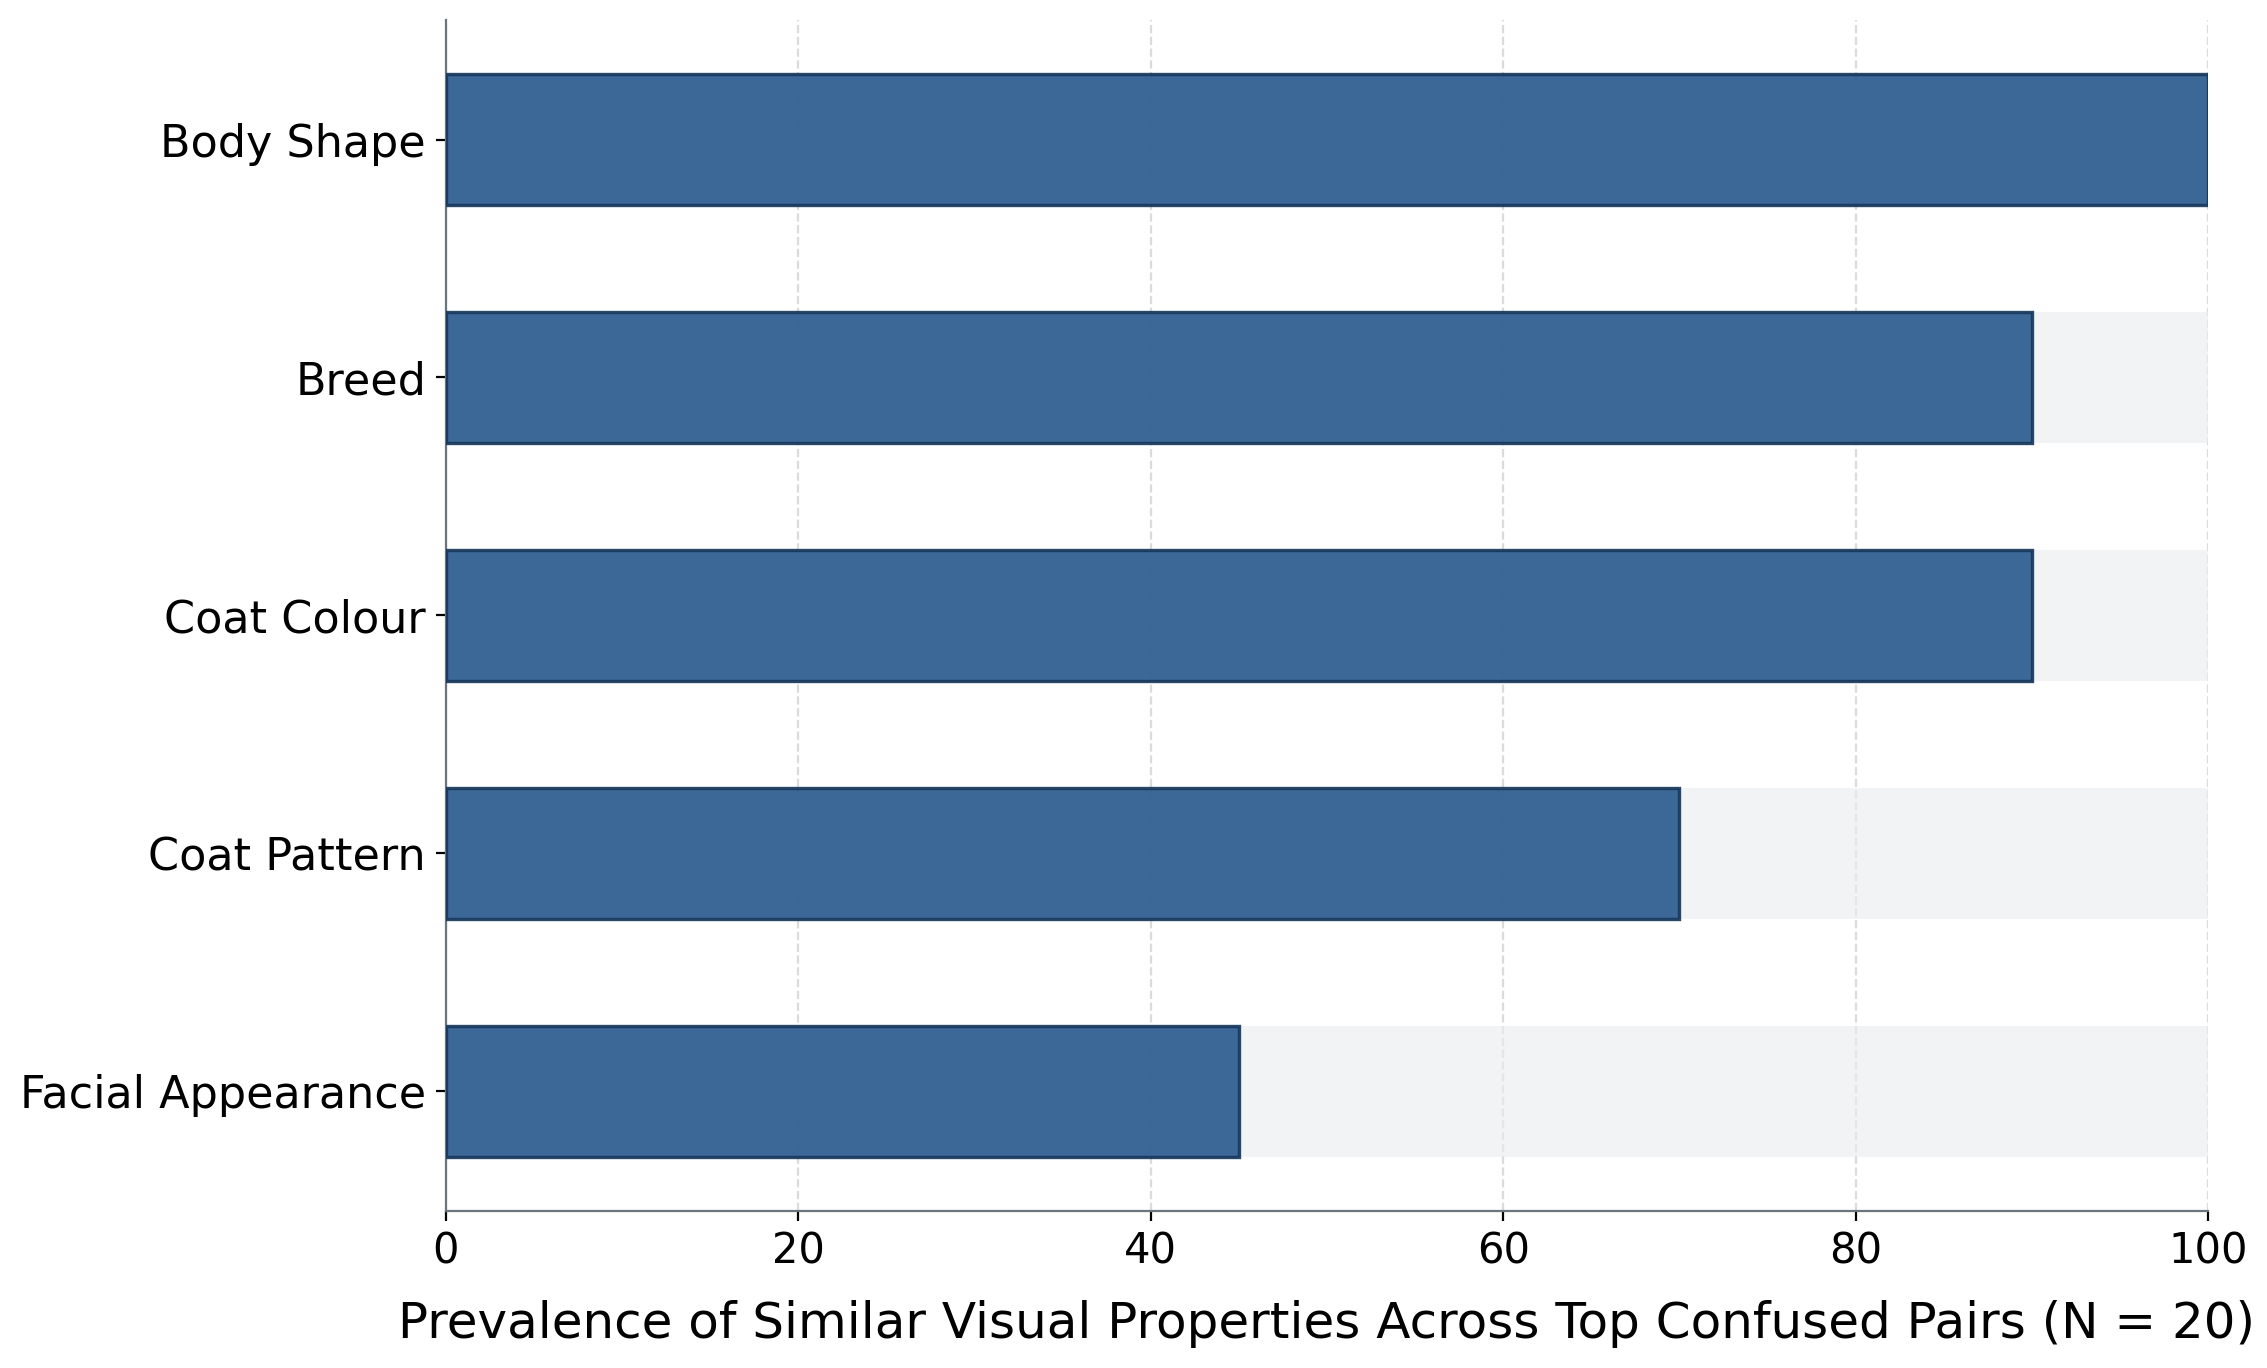

In [ ]:
# =====================================================================
# Bar Chart: Prevalence of Similar Visual Properties (Top 20 Pairs)
# Font sizes matched to Backbone Adaptation Depth figure
# =====================================================================

CONF_ANNOT_CSV = ROOT_DIR / "evaluation" / "failure_case" / "confusion_pairs_annotations.csv"
if not CONF_ANNOT_CSV.exists():
    CONF_ANNOT_CSV = ROOT_DIR / "evaluation" / "confusion_pairs_annotations.csv"

df_annot_conf = pd.read_csv(CONF_ANNOT_CSV)
n_pairs = len(df_annot_conf)

# CSV annotation values
properties = [
    ("Body Shape", "Body shape", "Similar"),
    ("Breed", "Breed match", "Same breed"),
    ("Coat Colour", "Coat colour", "Similar"),
    ("Coat Pattern", "Coat pattern", "Similar"),
    ("Facial Appearance", "Facial appearance", "Similar"),
]

records = []

for display_name, col_name, target_val in properties:

    count = (
        df_annot_conf[col_name]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq(target_val)
        .sum()
    )

    pct = (count / n_pairs) * 100.0 if n_pairs > 0 else 0.0

    records.append({
        "Visual Property": display_name,
        "Similarity Count": count,
        "Total Evaluated": n_pairs,
        "Similarity (%)": pct,
        "Non-Similarity Count": n_pairs - count,
        "Non-Similarity (%)": (
            (n_pairs - count) / n_pairs * 100.0
            if n_pairs > 0 else 0.0
        )
    })

df_summary = pd.DataFrame(records).sort_values(
    by="Similarity (%)",
    ascending=False
).reset_index(drop=True)

display(df_summary)


# =====================================================================
# Plot Publication Bar Chart
# =====================================================================

plot_df = df_summary.sort_values(
    by="Similarity (%)",
    ascending=True
).reset_index(drop=True)

fig, ax = plt.subplots(
    figsize=(11.5, 7.0),
    dpi=200
)

y_pos = np.arange(len(plot_df))

# Background bars to 100%
ax.barh(
    y_pos,
    [100] * len(plot_df),
    color="#e9ecef",
    height=0.55,
    zorder=2,
    alpha=0.6
)

# Similarity prevalence bars
bars = ax.barh(
    y_pos,
    plot_df["Similarity (%)"],
    color="#2b5c8f",
    edgecolor="#18385c",
    height=0.55,
    linewidth=1.2,
    zorder=3,
    alpha=0.92
)


# =====================================================================
# Figure Formatting
# =====================================================================

ax.set_yticks(y_pos)

ax.set_yticklabels(
    plot_df["Visual Property"],
    fontsize=16
)

ax.set_xlabel(
    f"Prevalence of Similar Visual Properties Across Top Confused Pairs (%)",
    fontsize=18,
    labelpad=10
)

ax.tick_params(
    axis="x",
    labelsize=15
)

ax.tick_params(
    axis="y",
    labelsize=16
)

ax.set_xlim(0, 100)

ax.xaxis.grid(
    True,
    linestyle="--",
    alpha=0.45,
    zorder=1
)

ax.set_axisbelow(True)

# Remove unnecessary spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#6c757d")
ax.spines["bottom"].set_color("#6c757d")

plt.tight_layout()


# =====================================================================
# Save Figure
# =====================================================================

FIG_DIR.mkdir(parents=True, exist_ok=True)

pdf_path = FIG_DIR / "confusion_properties_percentage.pdf"
png_path = FIG_DIR / "confusion_properties_percentage.png"

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"-> PDF saved to: {pdf_path.resolve()}")
print(f"-> PNG saved to: {png_path.resolve()}")

plt.show()

## 3. Gallery Size Sensitivity Analysis (Transferred from Ablations)

**Objective**: Quantify how retrieval accuracy scales as the size and composition of the gallery search pool varies.

We present two complementary scaling experiments:
1. **Experiment A (Total Gallery Video Volume Scaling)**: Fixed at all 777 unique gallery identities, varying the volume of distracting videos from $38.9\%$ (1 video per identity) to $100\%$ ($1,998$ videos).
2. **Experiment B (Distractor Identity Scaling)**: Varying the number of unique gallery identities from $N_{\text{IDs}} = 100$ up to $777$ identities, directly measuring how retrieval degrades as more competing individual dogs enter the gallery database.

In [13]:
# =====================================================================
# Experiment A: Total Gallery Video Volume Scaling (Transferred from Ablations)
# =====================================================================
from evaluation.evaluation_utils import _calc_closed_logic

gallery_steps = [
    {"pct": 38.9, "label": "38.9% (1 vid/ID)", "tick": "38.9%\n(777)", "n_vids": 777, "is_min": True},
    {"pct": 50.0, "label": "50.0%", "tick": "50.0%\n(999)", "n_vids": 999},
    {"pct": 60.0, "label": "60.0%", "tick": "60.0%\n(1,199)", "n_vids": 1199},
    {"pct": 70.0, "label": "70.0%", "tick": "70.0%\n(1,399)", "n_vids": 1399},
    {"pct": 80.0, "label": "80.0%", "tick": "80.0%\n(1,598)", "n_vids": 1598},
    {"pct": 90.0, "label": "90.0%", "tick": "90.0%\n(1,798)", "n_vids": 1798},
    {"pct": 100.0, "label": "100.0% (Full)", "tick": "100.0%\n(1,998)", "n_vids": 1998, "is_full": True},
]

CACHE_FILE_A = ROOT_DIR / "evaluation" / "cache_gallery_sensitivity.pkl"

if CACHE_FILE_A.exists() and CACHE_FILE_A.stat().st_mtime >= baseline_csv.stat().st_mtime:
    with open(CACHE_FILE_A, "rb") as f:
        gallery_summary_steps = pickle.load(f)
    print("-> [CACHE HIT] Loaded gallery volume sensitivity bootstrap results from cache!")
else:
    print("-> Computing 100-iteration bootstrap for gallery volume sensitivity...")
    rng = np.random.RandomState(42)
    N_BOOTSTRAP = 100
    N_GALLERY = len(gallery_labels)
    
    unique_g_pids = np.unique(gallery_labels)
    pid_to_indices = {pid: np.where(gallery_labels == pid)[0] for pid in unique_g_pids}
    
    gallery_summary_steps = []
    for step in gallery_steps:
        target_count = step["n_vids"]
        r1_boots = []
        map_boots = []
        
        for b in range(N_BOOTSTRAP):
            core_idx = [rng.choice(pid_to_indices[pid]) for pid in unique_g_pids]
            core_set = set(core_idx)
            remaining_pool = [i for i in range(N_GALLERY) if i not in core_set]
            
            n_needed = target_count - len(core_idx)
            if n_needed > 0:
                sampled_distractors = rng.choice(remaining_pool, size=n_needed, replace=False)
                sub_g_indices = np.array(core_idx + list(sampled_distractors))
            else:
                sub_g_indices = np.array(core_idx)
                
            sub_dist = dist_mat[:, sub_g_indices]
            sub_g_labels = gallery_labels[sub_g_indices]
            
            match_matrix = query_labels[:, None] == sub_g_labels[None, :]
            sort_idx = np.argsort(sub_dist, axis=1)
            sorted_matches = np.take_along_axis(match_matrix, sort_idx, axis=1)
            
            res = _calc_closed_logic(sorted_matches)
            r1_boots.append(res["cmc"][0] * 100)
            map_boots.append(res["mAP"] * 100)
            
        r1_mean = np.mean(r1_boots)
        r1_ci = (np.percentile(r1_boots, 2.5), np.percentile(r1_boots, 97.5))
        map_mean = np.mean(map_boots)
        map_ci = (np.percentile(map_boots, 2.5), np.percentile(map_boots, 97.5))
        
        gallery_summary_steps.append({
            **step,
            "r1": r1_mean,
            "r1_l": r1_ci[0],
            "r1_u": r1_ci[1],
            "map": map_mean,
            "map_l": map_ci[0],
            "map_u": map_ci[1],
        })
    with open(CACHE_FILE_A, "wb") as f:
        pickle.dump(gallery_summary_steps, f)
    print("-> Cached gallery volume sensitivity results.")

rows_vol = []
for s in gallery_summary_steps:
    rows_vol.append({
        "Gallery Scale": s["label"],
        "Num Videos": s["n_vids"],
        "Rank-1 (%) [95% CI]": f"{s['r1']:.1f} [{s['r1_l']:.1f}-{s['r1_u']:.1f}]",
        "mAP (%) [95% CI]": f"{s['map']:.1f} [{s['map_l']:.1f}-{s['map_u']:.1f}]"
    })
df_sens_vol = pd.DataFrame(rows_vol)
display(df_sens_vol)

-> [CACHE HIT] Loaded gallery volume sensitivity bootstrap results from cache!


,Gallery Scale,Num Videos,Rank-1 (%) [95% CI],mAP (%) [95% CI]
0,38.9% (1 vid/ID),777,51.6 [49.5-53.6],62.8 [61.2-64.1]
1,50.0%,999,53.5 [51.7-55.1],61.2 [59.9-62.3]
2,60.0%,1199,55.5 [54.1-56.9],60.1 [59.2-61.0]
3,70.0%,1399,57.3 [55.8-58.6],59.4 [58.5-60.4]
4,80.0%,1598,59.0 [57.9-60.0],58.8 [58.0-59.3]
5,90.0%,1798,60.6 [59.8-61.3],58.2 [57.7-58.7]
6,100.0% (Full),1998,62.1 [62.1-62.1],57.8 [57.8-57.8]


In [14]:
# =====================================================================
# Experiment B: Gallery Identity Scaling (Distractor ID Scaling)
# Directly measures degradation as unique competing dog identities increase
# =====================================================================
id_steps = [100, 200, 300, 400, 500, 600, 777]
CACHE_FILE_B = ROOT_DIR / "evaluation" / "cache_gallery_identity_sensitivity.pkl"

if CACHE_FILE_B.exists() and CACHE_FILE_B.stat().st_mtime >= baseline_csv.stat().st_mtime:
    with open(CACHE_FILE_B, "rb") as f:
        id_summary_steps = pickle.load(f)
    print("-> [CACHE HIT] Loaded gallery identity scaling bootstrap results from cache!")
else:
    print("-> Computing 100-iteration bootstrap for gallery identity scaling...")
    rng = np.random.RandomState(42)
    N_BOOTSTRAP = 100
    unique_g_pids = np.unique(gallery_labels)
    
    id_summary_steps = []
    for n_id in id_steps:
        r1_boots = []
        map_boots = []
        
        for b in range(N_BOOTSTRAP):
            if n_id == len(unique_g_pids):
                sampled_pids = set(unique_g_pids)
            else:
                sampled_pids = set(rng.choice(unique_g_pids, size=n_id, replace=False))
                
            sub_g_idx = [i for i, pid in enumerate(gallery_labels) if pid in sampled_pids]
            sub_dist = dist_mat[:, sub_g_idx]
            sub_g_labels = gallery_labels[sub_g_idx]
            
            valid_q_idx = [i for i, qpid in enumerate(query_labels) if qpid in sampled_pids]
            q_sub_dist = sub_dist[valid_q_idx]
            q_sub_labels = query_labels[valid_q_idx]
            
            match_matrix = q_sub_labels[:, None] == sub_g_labels[None, :]
            sort_idx = np.argsort(q_sub_dist, axis=1)
            sorted_matches = np.take_along_axis(match_matrix, sort_idx, axis=1)
            
            res = _calc_closed_logic(sorted_matches)
            r1_boots.append(res["cmc"][0] * 100)
            map_boots.append(res["mAP"] * 100)
            
        r1_mean = np.mean(r1_boots)
        r1_ci = (np.percentile(r1_boots, 2.5), np.percentile(r1_boots, 97.5))
        map_mean = np.mean(map_boots)
        map_ci = (np.percentile(map_boots, 2.5), np.percentile(map_boots, 97.5))
        
        id_summary_steps.append({
            'n_identities': n_id,
            'pct_of_total': (n_id / len(unique_g_pids)) * 100.0,
            'r1': r1_mean, 'r1_l': r1_ci[0], 'r1_u': r1_ci[1],
            'map': map_mean, 'map_l': map_ci[0], 'map_u': map_ci[1]
        })
    with open(CACHE_FILE_B, "wb") as f:
        pickle.dump(id_summary_steps, f)
    print("-> Cached gallery identity scaling results.")

rows_id = []
for s in id_summary_steps:
    rows_id.append({
        "Num Gallery IDs": s["n_identities"],
        "% of Total Population": f"{s['pct_of_total']:.1f}%",
        "Rank-1 (%) [95% CI]": f"{s['r1']:.1f} [{s['r1_l']:.1f}-{s['r1_u']:.1f}]",
        "mAP (%) [95% CI]": f"{s['map']:.1f} [{s['map_l']:.1f}-{s['map_u']:.1f}]"
    })
df_sens_id = pd.DataFrame(rows_id)
display(df_sens_id)

-> [CACHE HIT] Loaded gallery identity scaling bootstrap results from cache!


,Num Gallery IDs,% of Total Population,Rank-1 (%) [95% CI],mAP (%) [95% CI]
0,100,12.9%,82.5 [76.4-89.9],80.7 [75.3-86.3]
1,200,25.7%,75.2 [70.2-80.1],73.1 [69.6-76.8]
2,300,38.6%,71.6 [67.7-74.8],68.7 [66.0-71.1]
3,400,51.5%,68.5 [65.5-71.1],65.5 [63.5-67.3]
4,500,64.4%,66.6 [64.3-68.7],62.9 [61.1-64.8]
5,600,77.2%,64.5 [62.9-66.4],60.6 [59.3-62.0]
6,777,100.0%,62.1 [62.1-62.1],57.8 [57.8-57.8]


-> Saved combined gallery sensitivity figure to c:\Users\marko\Desktop\DogReID-1553\evaluation\figures\gallery_sensitivity_combined.png


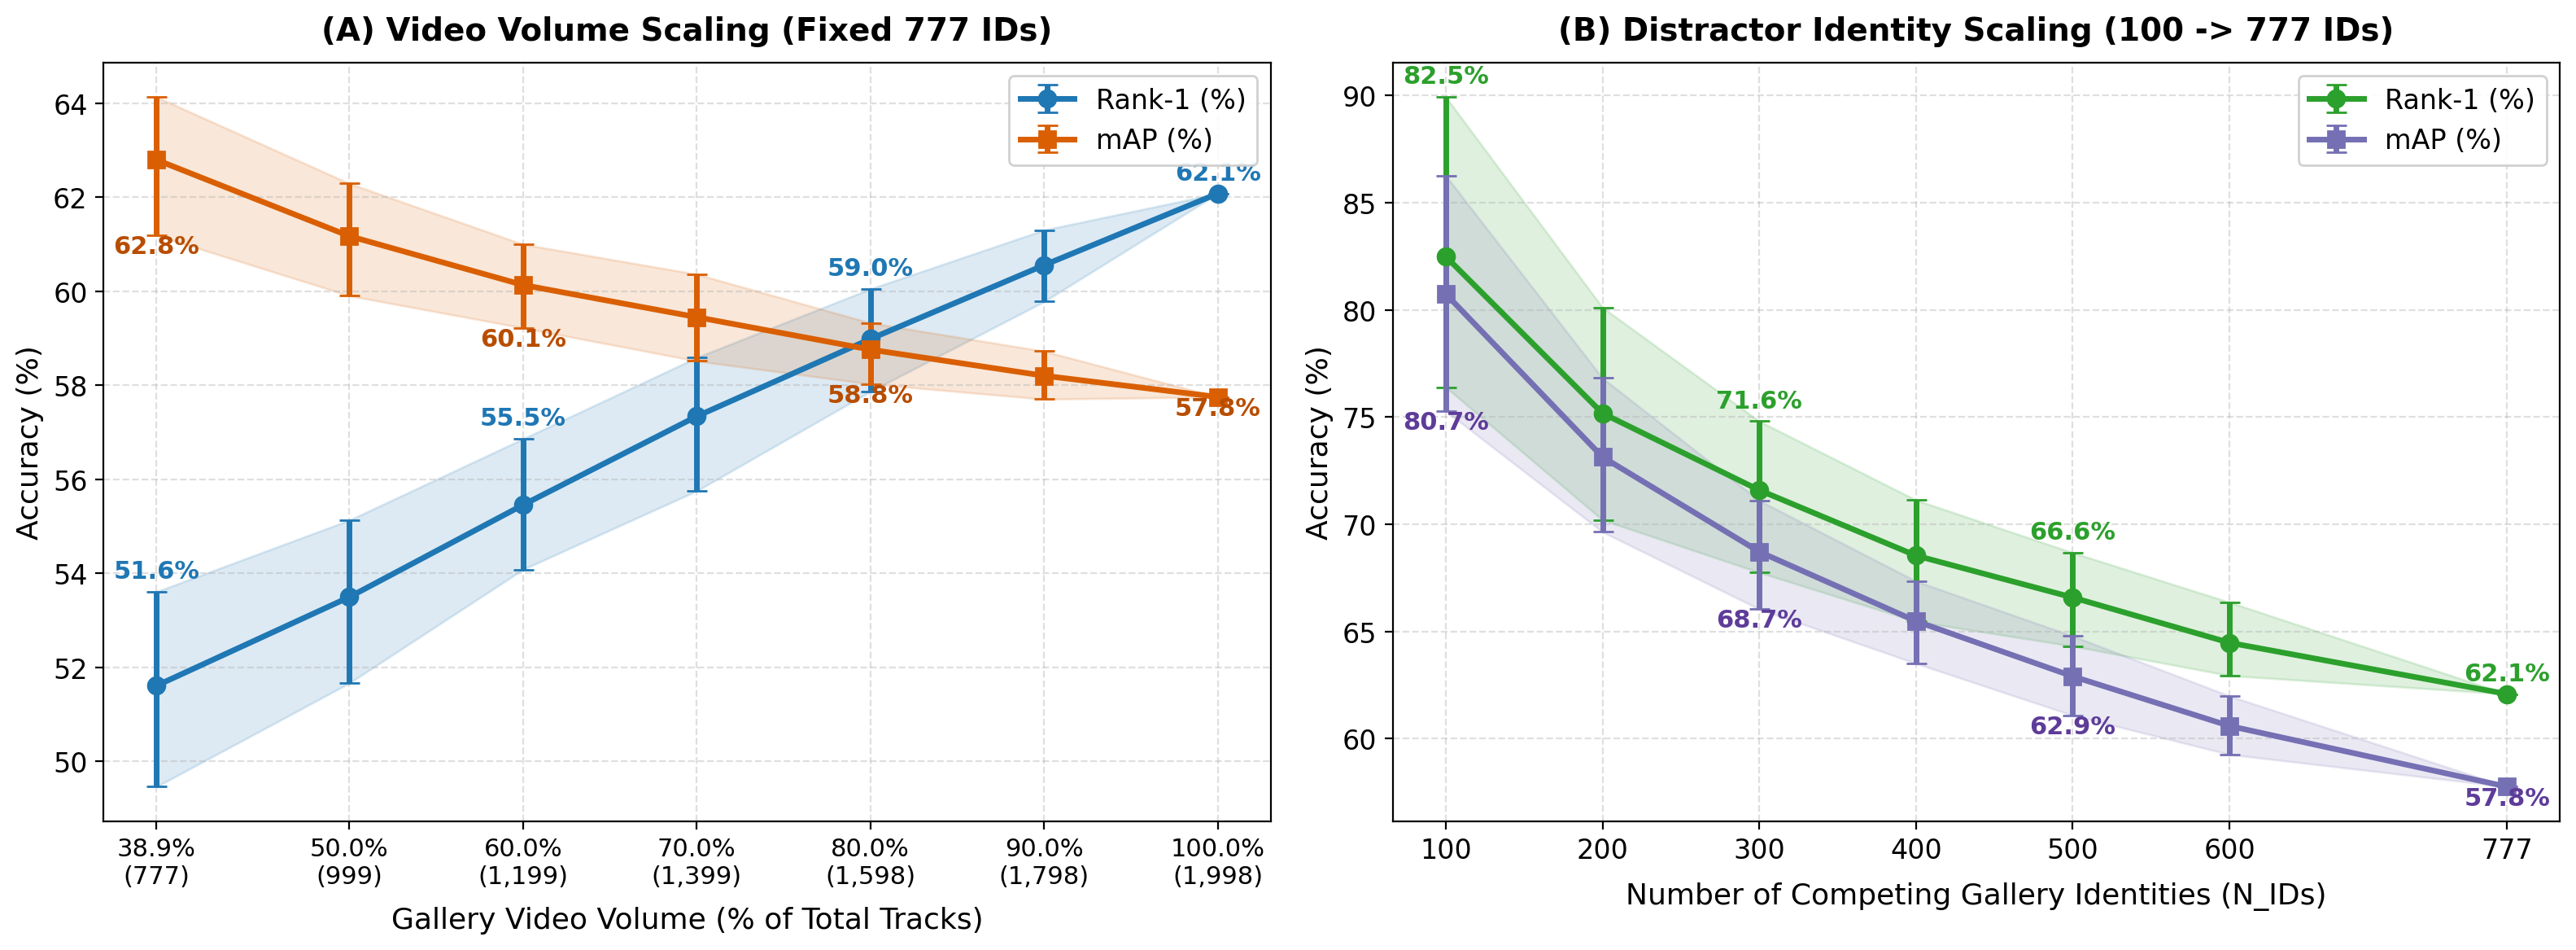

In [15]:
# =====================================================================
# Publication Plot: Side-by-Side Gallery Sensitivity Curves
# Left: Video Volume Scaling | Right: Distractor Identity Scaling
# =====================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.0), dpi=200)

# 1. Left Plot: Video Volume Scaling
x_v = np.array([s["pct"] for s in gallery_steps])
labels_v = [s["tick"] for s in gallery_steps]
r1_v = np.array([s["r1"] for s in gallery_summary_steps])
r1_l_v = np.array([s["r1_l"] for s in gallery_summary_steps])
r1_u_v = np.array([s["r1_u"] for s in gallery_summary_steps])
map_v = np.array([s["map"] for s in gallery_summary_steps])
map_l_v = np.array([s["map_l"] for s in gallery_summary_steps])
map_u_v = np.array([s["map_u"] for s in gallery_summary_steps])

ax1.fill_between(x_v, r1_l_v, r1_u_v, color="#1f77b4", alpha=0.15)
ax1.fill_between(x_v, map_l_v, map_u_v, color="#d95f02", alpha=0.15)
ax1.errorbar(x_v, r1_v, yerr=[np.maximum(0, r1_v-r1_l_v), np.maximum(0, r1_u_v-r1_v)],
             fmt="-o", color="#1f77b4", label="Rank-1 (%)", linewidth=2.5, markersize=7.5, capsize=4.5)
ax1.errorbar(x_v, map_v, yerr=[np.maximum(0, map_v-map_l_v), np.maximum(0, map_u_v-map_v)],
             fmt="-s", color="#d95f02", label="mAP (%)", linewidth=2.5, markersize=7.5, capsize=4.5)

for idx in [0, 2, 4, 6]:
    ax1.annotate(f"{r1_v[idx]:.1f}%", xy=(x_v[idx], r1_u_v[idx]), xytext=(0, 6),
                 textcoords="offset points", ha="center", fontsize=11, color="#1f77b4", weight="bold")
    ax1.annotate(f"{map_v[idx]:.1f}%", xy=(x_v[idx], map_l_v[idx]), xytext=(0, -8),
                 textcoords="offset points", ha="center", fontsize=11, color="#b84d00", weight="bold")

ax1.set_xticks(x_v)
ax1.set_xticklabels(labels_v, fontsize=11)
ax1.set_xlabel("Gallery Video Volume (% of Total Tracks)", fontsize=13, labelpad=8)
ax1.set_ylabel("Accuracy (%)", fontsize=13)
ax1.set_title("(A) Video Volume Scaling (Fixed 777 IDs)", fontsize=14, weight="bold", pad=10)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="upper right", framealpha=0.9, fontsize=12)

# 2. Right Plot: Distractor Identity Scaling
x_id = np.array([s["n_identities"] for s in id_summary_steps])
r1_id = np.array([s["r1"] for s in id_summary_steps])
r1_l_id = np.array([s["r1_l"] for s in id_summary_steps])
r1_u_id = np.array([s["r1_u"] for s in id_summary_steps])
map_id = np.array([s["map"] for s in id_summary_steps])
map_l_id = np.array([s["map_l"] for s in id_summary_steps])
map_u_id = np.array([s["map_u"] for s in id_summary_steps])

ax2.fill_between(x_id, r1_l_id, r1_u_id, color="#2ca02c", alpha=0.15)
ax2.fill_between(x_id, map_l_id, map_u_id, color="#7570b3", alpha=0.15)
ax2.errorbar(x_id, r1_id, yerr=[np.maximum(0, r1_id-r1_l_id), np.maximum(0, r1_u_id-r1_id)],
             fmt="-o", color="#2ca02c", label="Rank-1 (%)", linewidth=2.5, markersize=7.5, capsize=4.5)
ax2.errorbar(x_id, map_id, yerr=[np.maximum(0, map_id-map_l_id), np.maximum(0, map_u_id-map_id)],
             fmt="-s", color="#7570b3", label="mAP (%)", linewidth=2.5, markersize=7.5, capsize=4.5)

for idx in [0, 2, 4, 6]:
    ax2.annotate(f"{r1_id[idx]:.1f}%", xy=(x_id[idx], r1_u_id[idx]), xytext=(0, 6),
                 textcoords="offset points", ha="center", fontsize=11, color="#2ca02c", weight="bold")
    ax2.annotate(f"{map_id[idx]:.1f}%", xy=(x_id[idx], map_l_id[idx]), xytext=(0, -8),
                 textcoords="offset points", ha="center", fontsize=11, color="#5e3c99", weight="bold")

ax2.set_xticks(x_id)
ax2.set_xlabel("Number of Competing Gallery Identities (N_IDs)", fontsize=13, labelpad=8)
ax2.set_ylabel("Accuracy (%)", fontsize=13)
ax2.set_title("(B) Distractor Identity Scaling (100 -> 777 IDs)", fontsize=14, weight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(loc="upper right", framealpha=0.9, fontsize=12)

plt.tight_layout()
plt.savefig(FIG_DIR / 'gallery_sensitivity_combined.png', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'gallery_sensitivity_combined.pdf', bbox_inches='tight')
print(f"-> Saved combined gallery sensitivity figure to {FIG_DIR / 'gallery_sensitivity_combined.png'}")
plt.show()